# 04 — Train baseline LSTM on UCF101 group-aware split v1

This is the training notebook paired with `03_rebuild_sequences_group_split_v1.ipynb`. It trains from scratch on arrays saved in `data/processed/sequences_group_split_v1/`.

- Uses read-only memory-mapped arrays and minibatches.
- Uses **batch size 8** to keep per-batch memory use low.
- Verifies source-video and recording-group isolation before training.
- Selects the best checkpoint using validation macro-F1.
- Saves model/history/plots/reports under **new filenames**; it does not overwrite earlier experiments.

Run this only after the group-split sequence builder finishes successfully. This is a fresh baseline trained on the new split, so do not load a checkpoint trained on `sequences_all/`.

Note: this is a group-aware randomized 60/20/20 split, not an official UCF101 split-list benchmark.

In [1]:
from pathlib import Path
import json
import random
import copy
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

PROJECT_DIR = Path(r"C:\Users\admin\ViTPose_Action_Recognition")
SEQUENCE_DIR = PROJECT_DIR / "data" / "processed" / "sequences_group_split_v1"
OUTPUT_MODEL_DIR = PROJECT_DIR / "outputs" / "models"
OUTPUT_REPORT_DIR = PROJECT_DIR / "outputs" / "reports"
OUTPUT_MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)
print("Sequence data:", SEQUENCE_DIR)
print("Sequence folder exists:", SEQUENCE_DIR.is_dir())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
assert SEQUENCE_DIR.is_dir(), f"Sequence folder not found: {SEQUENCE_DIR}"

Project: C:\Users\admin\ViTPose_Action_Recognition
Sequence data: C:\Users\admin\ViTPose_Action_Recognition\data\processed\sequences_group_split_v1
Sequence folder exists: True
PyTorch: 2.7.1+cu118
CUDA available: True
GPU: NVIDIA RTX A4000


In [2]:
# Reproducibility and memory-mapped loading
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
required_files = [
    "X_train.npy", "y_train.npy", "X_val.npy", "y_val.npy",
    "X_test.npy", "y_test.npy", "videos_train.npy", "videos_val.npy",
    "videos_test.npy", "label_map.json"
]
missing = [name for name in required_files if not (SEQUENCE_DIR / name).is_file()]
assert not missing, f"Missing files: {missing}. Finish the sequence-building notebook first."

# mmap_mode='r' keeps large feature arrays on disk and reads samples on demand.
X_train = np.load(SEQUENCE_DIR / "X_train.npy", mmap_mode="r", allow_pickle=False)
y_train = np.load(SEQUENCE_DIR / "y_train.npy", mmap_mode="r", allow_pickle=False)
X_val = np.load(SEQUENCE_DIR / "X_val.npy", mmap_mode="r", allow_pickle=False)
y_val = np.load(SEQUENCE_DIR / "y_val.npy", mmap_mode="r", allow_pickle=False)
X_test = np.load(SEQUENCE_DIR / "X_test.npy", mmap_mode="r", allow_pickle=False)
y_test = np.load(SEQUENCE_DIR / "y_test.npy", mmap_mode="r", allow_pickle=False)
videos_train = np.load(SEQUENCE_DIR / "videos_train.npy", mmap_mode="r", allow_pickle=False)
videos_val = np.load(SEQUENCE_DIR / "videos_val.npy", mmap_mode="r", allow_pickle=False)
videos_test = np.load(SEQUENCE_DIR / "videos_test.npy", mmap_mode="r", allow_pickle=False)

label_map = json.loads((SEQUENCE_DIR / "label_map.json").read_text(encoding="utf-8"))
id_to_label = {int(k): str(v) for k, v in label_map.items()}
class_ids = sorted(id_to_label)
class_names = [id_to_label[i] for i in class_ids]
NUM_CLASSES = len(class_names)

print("Device:", DEVICE)
print("Classes:", NUM_CLASSES)
print("Label map:", id_to_label)
print("Train:", X_train.shape, y_train.shape, "| videos:", len(np.unique(videos_train)))
print("Validation:", X_val.shape, y_val.shape, "| videos:", len(np.unique(videos_val)))
print("Test:", X_test.shape, y_test.shape, "| videos:", len(np.unique(videos_test)))

Device: cuda:0
Classes: 101
Label map: {0: 'ApplyEyeMakeup', 1: 'ApplyLipstick', 2: 'Archery', 3: 'BabyCrawling', 4: 'BalanceBeam', 5: 'BandMarching', 6: 'BaseballPitch', 7: 'Basketball', 8: 'BasketballDunk', 9: 'BenchPress', 10: 'Biking', 11: 'Billiards', 12: 'BlowDryHair', 13: 'BlowingCandles', 14: 'BodyWeightSquats', 15: 'Bowling', 16: 'BoxingPunchingBag', 17: 'BoxingSpeedBag', 18: 'BreastStroke', 19: 'BrushingTeeth', 20: 'CleanAndJerk', 21: 'CliffDiving', 22: 'CricketBowling', 23: 'CricketShot', 24: 'CuttingInKitchen', 25: 'Diving', 26: 'Drumming', 27: 'Fencing', 28: 'FieldHockeyPenalty', 29: 'FloorGymnastics', 30: 'FrisbeeCatch', 31: 'FrontCrawl', 32: 'GolfSwing', 33: 'Haircut', 34: 'HammerThrow', 35: 'Hammering', 36: 'HandstandPushups', 37: 'HandstandWalking', 38: 'HeadMassage', 39: 'HighJump', 40: 'HorseRace', 41: 'HorseRiding', 42: 'HulaHoop', 43: 'IceDancing', 44: 'JavelinThrow', 45: 'JugglingBalls', 46: 'JumpRope', 47: 'JumpingJack', 48: 'Kayaking', 49: 'Knitting', 50: 'LongJ

In [3]:
# Validate dimensions, labels and source-video split isolation
assert X_train.ndim == X_val.ndim == X_test.ndim == 3
assert X_train.shape[1:] == X_val.shape[1:] == X_test.shape[1:], "Sequence dimensions differ."
assert X_train.shape[2] == 51, "Expected 51 features per frame (17 joints x/y/confidence)."
assert len(X_train) == len(y_train) == len(videos_train)
assert len(X_val) == len(y_val) == len(videos_val)
assert len(X_test) == len(y_test) == len(videos_test)
assert len(X_train) and len(X_val) and len(X_test), "One of the splits is empty."

for split_name, y in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    unique, counts = np.unique(y, return_counts=True)
    found = set(unique.tolist())
    missing_names = [id_to_label[i] for i in class_ids if i not in found]
    print(f"{split_name} windows by class:", {
        id_to_label[int(k)]: int(v) for k, v in zip(unique, counts)
    })
    if missing_names:
        print("  WARNING: classes with no windows in this split:", missing_names)

train_video_set = set(np.unique(videos_train).tolist())
val_video_set = set(np.unique(videos_val).tolist())
test_video_set = set(np.unique(videos_test).tolist())
assert not train_video_set & val_video_set, "Source-video leakage between train and validation."
assert not train_video_set & test_video_set, "Source-video leakage between train and test."
assert not val_video_set & test_video_set, "Source-video leakage between validation and test."

# Additional group-level leakage check from the builder's manifest.
split_manifest_path = SEQUENCE_DIR / "video_split_manifest.csv"
assert split_manifest_path.is_file(), f"Missing split manifest: {split_manifest_path}"
split_manifest = pd.read_csv(split_manifest_path)
assert {"recording_group_key", "split"}.issubset(split_manifest.columns), (
    "Split manifest lacks group columns; rebuild the sequences with the group-aware notebook."
)
group_split_counts = split_manifest.groupby("recording_group_key")["split"].nunique()
leaked_groups = group_split_counts[group_split_counts > 1]
assert leaked_groups.empty, (
    "Recording-group leakage detected across splits: " + str(leaked_groups.index[:10].tolist())
)
print("No source-video overlap; no recording-group overlap detected.")

train_counts = np.bincount(np.asarray(y_train, dtype=np.int64), minlength=NUM_CLASSES)
zero_train = [id_to_label[i] for i, n in enumerate(train_counts) if n == 0]
assert not zero_train, (
    f"No training windows for classes {zero_train}. Return to the sequence-builder audit; "
    "do not train a classifier that cannot learn these classes."
)
print("No source-video leakage detected. Sequence length:", X_train.shape[1])

train windows by class: {'ApplyEyeMakeup': 688, 'ApplyLipstick': 596, 'Archery': 757, 'BabyCrawling': 577, 'BalanceBeam': 258, 'BandMarching': 979, 'BaseballPitch': 351, 'Basketball': 426, 'BasketballDunk': 149, 'BenchPress': 412, 'Biking': 749, 'Billiards': 1056, 'BlowDryHair': 966, 'BlowingCandles': 226, 'BodyWeightSquats': 359, 'Bowling': 423, 'BoxingPunchingBag': 871, 'BoxingSpeedBag': 892, 'BreastStroke': 19, 'BrushingTeeth': 813, 'CleanAndJerk': 682, 'CliffDiving': 65, 'CricketBowling': 297, 'CricketShot': 289, 'CuttingInKitchen': 483, 'Diving': 385, 'Drumming': 1026, 'Fencing': 350, 'FieldHockeyPenalty': 350, 'FloorGymnastics': 450, 'FrisbeeCatch': 232, 'FrontCrawl': 117, 'GolfSwing': 741, 'Haircut': 603, 'HammerThrow': 654, 'Hammering': 371, 'HandstandPushups': 284, 'HandstandWalking': 320, 'HeadMassage': 777, 'HighJump': 269, 'HorseRace': 732, 'HorseRiding': 594, 'HulaHoop': 313, 'IceDancing': 1205, 'JavelinThrow': 229, 'JugglingBalls': 917, 'JumpRope': 2072, 'JumpingJack': 17

## Model and batch settings

The LSTM receives 16 consecutive sampled poses (or the sequence length stored by the builder) and predicts one of the action classes. The class-weighted loss helps when some classes have more windows than others. It does not fix poor pose quality or a biased split.

In [4]:
# Tune only if needed. Lower BATCH_SIZE if CUDA runs out of memory.
BATCH_SIZE = 8
HIDDEN_SIZE = 128
NUM_LAYERS = 1
DROPOUT = 0.35
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 80
PATIENCE = 10
NUM_WORKERS = 0

class PoseSequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        # Copy one sequence at a time from the read-only memory map.
        x = np.array(self.X[idx], dtype=np.float32, copy=True)
        y = int(self.y[idx])
        return torch.from_numpy(x), torch.tensor(y, dtype=torch.long)

train_dataset = PoseSequenceDataset(X_train, y_train)
val_dataset = PoseSequenceDataset(X_val, y_val)
test_dataset = PoseSequenceDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))

class PoseLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, num_classes, dropout):
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_classes)
    def forward(self, x):
        _, (h_n, _) = self.lstm(x)
        return self.classifier(self.dropout(h_n[-1]))

model = PoseLSTM(51, HIDDEN_SIZE, NUM_LAYERS, NUM_CLASSES, DROPOUT).to(DEVICE)
class_weights = len(y_train) / (NUM_CLASSES * train_counts.astype(np.float64))
class_weights_t = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights_t)
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

print(model)
print("Train windows:", len(train_dataset), "| batch size:", BATCH_SIZE)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

PoseLSTM(
  (lstm): LSTM(51, 128, batch_first=True)
  (dropout): Dropout(p=0.35, inplace=False)
  (classifier): Linear(in_features=128, out_features=101, bias=True)
)
Train windows: 61747 | batch size: 8
Trainable parameters: 105701


In [5]:
def run_epoch(model, loader, train_mode):
    model.train(train_mode)
    total_loss = 0.0
    total_count = 0
    truths, predictions = [], []
    context = torch.enable_grad if train_mode else torch.no_grad
    with context():
        for xb, yb in loader:
            xb = xb.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
            yb = yb.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
            if train_mode:
                optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            if train_mode:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            total_loss += float(loss.item()) * len(yb)
            total_count += len(yb)
            truths.append(yb.detach().cpu().numpy())
            predictions.append(logits.argmax(dim=1).detach().cpu().numpy())
    y_true = np.concatenate(truths) if truths else np.array([], dtype=np.int64)
    y_pred = np.concatenate(predictions) if predictions else np.array([], dtype=np.int64)
    avg_loss = total_loss / max(total_count, 1)
    acc = accuracy_score(y_true, y_pred) if total_count else 0.0
    macro_f1 = f1_score(y_true, y_pred, labels=class_ids, average="macro", zero_division=0) if total_count else 0.0
    bal_acc = balanced_accuracy_score(y_true, y_pred) if total_count else 0.0
    return avg_loss, acc, macro_f1, bal_acc

print("Training/evaluation helpers ready.")

Training/evaluation helpers ready.


In [6]:
MODEL_PATH = OUTPUT_MODEL_DIR / "lstm_action_model_ucf101_group_split_v1.pt"
HISTORY_PATH = OUTPUT_REPORT_DIR / "lstm_ucf101_group_split_v1_training_history.csv"

history = []
best_val_f1 = -1.0
best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_acc, train_f1, train_bal_acc = run_epoch(model, train_loader, True)
    val_loss, val_acc, val_f1, val_bal_acc = run_epoch(model, val_loader, False)
    row = {
        "epoch": epoch, "train_loss": train_loss, "train_accuracy": train_acc,
        "train_macro_f1": train_f1, "train_balanced_accuracy": train_bal_acc,
        "val_loss": val_loss, "val_accuracy": val_acc,
        "val_macro_f1": val_f1, "val_balanced_accuracy": val_bal_acc,
    }
    history.append(row)
    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | train loss={train_loss:.4f}, "
        f"acc={train_acc:.3f}, macro-F1={train_f1:.3f} | "
        f"val loss={val_loss:.4f}, acc={val_acc:.3f}, macro-F1={val_f1:.3f}",
        flush=True
    )
    improved = (val_f1 > best_val_f1 + 1e-6) or (
        abs(val_f1 - best_val_f1) <= 1e-6 and val_loss < best_val_loss
    )
    if improved:
        best_val_f1, best_val_loss, best_epoch = val_f1, val_loss, epoch
        checkpoint = {
            "model_state": copy.deepcopy(model.state_dict()),
            "input_size": 51,
            "sequence_length": int(X_train.shape[1]),
            "hidden_size": HIDDEN_SIZE,
            "num_layers": NUM_LAYERS,
            "dropout": DROPOUT,
            "num_classes": NUM_CLASSES,
            "label_map": label_map,
            "best_epoch": best_epoch,
            "best_val_macro_f1": best_val_f1,
            "best_val_loss": best_val_loss,
        }
        torch.save(checkpoint, MODEL_PATH)
        epochs_without_improvement = 0
        print("  Saved best validation checkpoint:", MODEL_PATH.name, flush=True)
    else:
        epochs_without_improvement += 1
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping: no validation macro-F1 improvement for {PATIENCE} epochs.")
        break

assert MODEL_PATH.is_file(), "No model checkpoint was saved."
print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation macro-F1:", round(best_val_f1, 4))
print("Model:", MODEL_PATH.resolve())
print("History:", HISTORY_PATH.resolve())

Epoch 01/80 | train loss=3.3789, acc=0.184, macro-F1=0.132 | val loss=2.9248, acc=0.257, macro-F1=0.167
  Saved best validation checkpoint: lstm_action_model_ucf101_group_split_v1.pt
Epoch 02/80 | train loss=2.5642, acc=0.372, macro-F1=0.295 | val loss=2.6920, acc=0.310, macro-F1=0.232
  Saved best validation checkpoint: lstm_action_model_ucf101_group_split_v1.pt
Epoch 03/80 | train loss=2.1840, acc=0.464, macro-F1=0.387 | val loss=2.7041, acc=0.319, macro-F1=0.250
  Saved best validation checkpoint: lstm_action_model_ucf101_group_split_v1.pt
Epoch 04/80 | train loss=1.9333, acc=0.525, macro-F1=0.449 | val loss=2.6698, acc=0.355, macro-F1=0.291
  Saved best validation checkpoint: lstm_action_model_ucf101_group_split_v1.pt
Epoch 05/80 | train loss=1.7412, acc=0.569, macro-F1=0.497 | val loss=2.8425, acc=0.340, macro-F1=0.285
Epoch 06/80 | train loss=1.5994, acc=0.605, macro-F1=0.537 | val loss=2.7518, acc=0.360, macro-F1=0.294
  Saved best validation checkpoint: lstm_action_model_ucf101

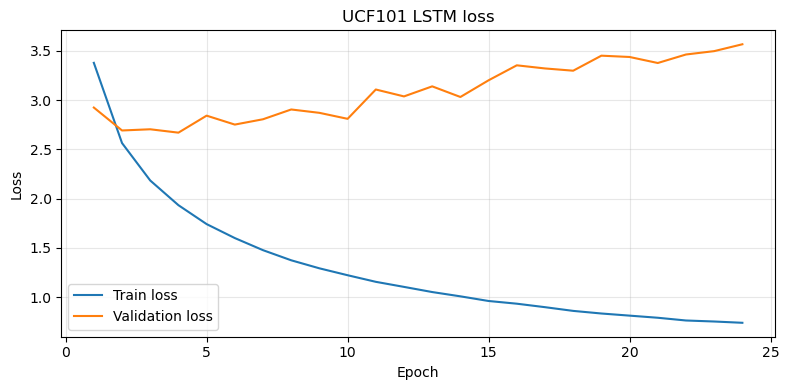

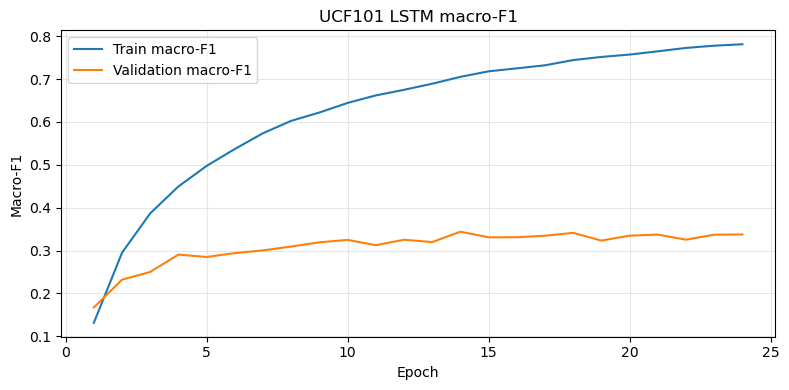

Saved plots: C:\Users\admin\ViTPose_Action_Recognition\outputs\reports\lstm_ucf101_group_split_v1_loss.png C:\Users\admin\ViTPose_Action_Recognition\outputs\reports\lstm_ucf101_group_split_v1_macro_f1.png


In [7]:
# Plot history
hist_df = pd.read_csv(HISTORY_PATH)
plt.figure(figsize=(8, 4))
plt.plot(hist_df["epoch"], hist_df["train_loss"], label="Train loss")
plt.plot(hist_df["epoch"], hist_df["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("UCF101 LSTM loss")
plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout()
loss_plot_path = OUTPUT_REPORT_DIR / "lstm_ucf101_group_split_v1_loss.png"
plt.savefig(loss_plot_path, dpi=160); plt.show()

plt.figure(figsize=(8, 4))
plt.plot(hist_df["epoch"], hist_df["train_macro_f1"], label="Train macro-F1")
plt.plot(hist_df["epoch"], hist_df["val_macro_f1"], label="Validation macro-F1")
plt.xlabel("Epoch"); plt.ylabel("Macro-F1"); plt.title("UCF101 LSTM macro-F1")
plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout()
f1_plot_path = OUTPUT_REPORT_DIR / "lstm_ucf101_group_split_v1_macro_f1.png"
plt.savefig(f1_plot_path, dpi=160); plt.show()
print("Saved plots:", loss_plot_path, f1_plot_path)

C:\Users\admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Best checkpoint epoch: 14
Test accuracy: 0.4097
Test balanced accuracy: 0.3717
Test macro-F1: 0.3546
Test windows: 21960
Test source videos: 2435

Classification report:
                     precision    recall  f1-score   support

    ApplyEyeMakeup       0.29      0.24      0.26       267
     ApplyLipstick       0.49      0.58      0.53       185
           Archery       0.37      0.34      0.35       165
      BabyCrawling       0.54      0.77      0.63       152
       BalanceBeam       0.22      0.08      0.12       135
      BandMarching       0.22      0.19      0.20       280
     BaseballPitch       0.35      0.59      0.44        85
        Basketball       0.09      0.06      0.07       131
    BasketballDunk       0.19      0.28      0.23        57
        BenchPress       0.46      0.64      0.54       152
            Biking       0.41      0.42      0.42       171
         Billiards       0.48      0.53      0.50       413
       BlowDryHair       0.22      0.13      0.1

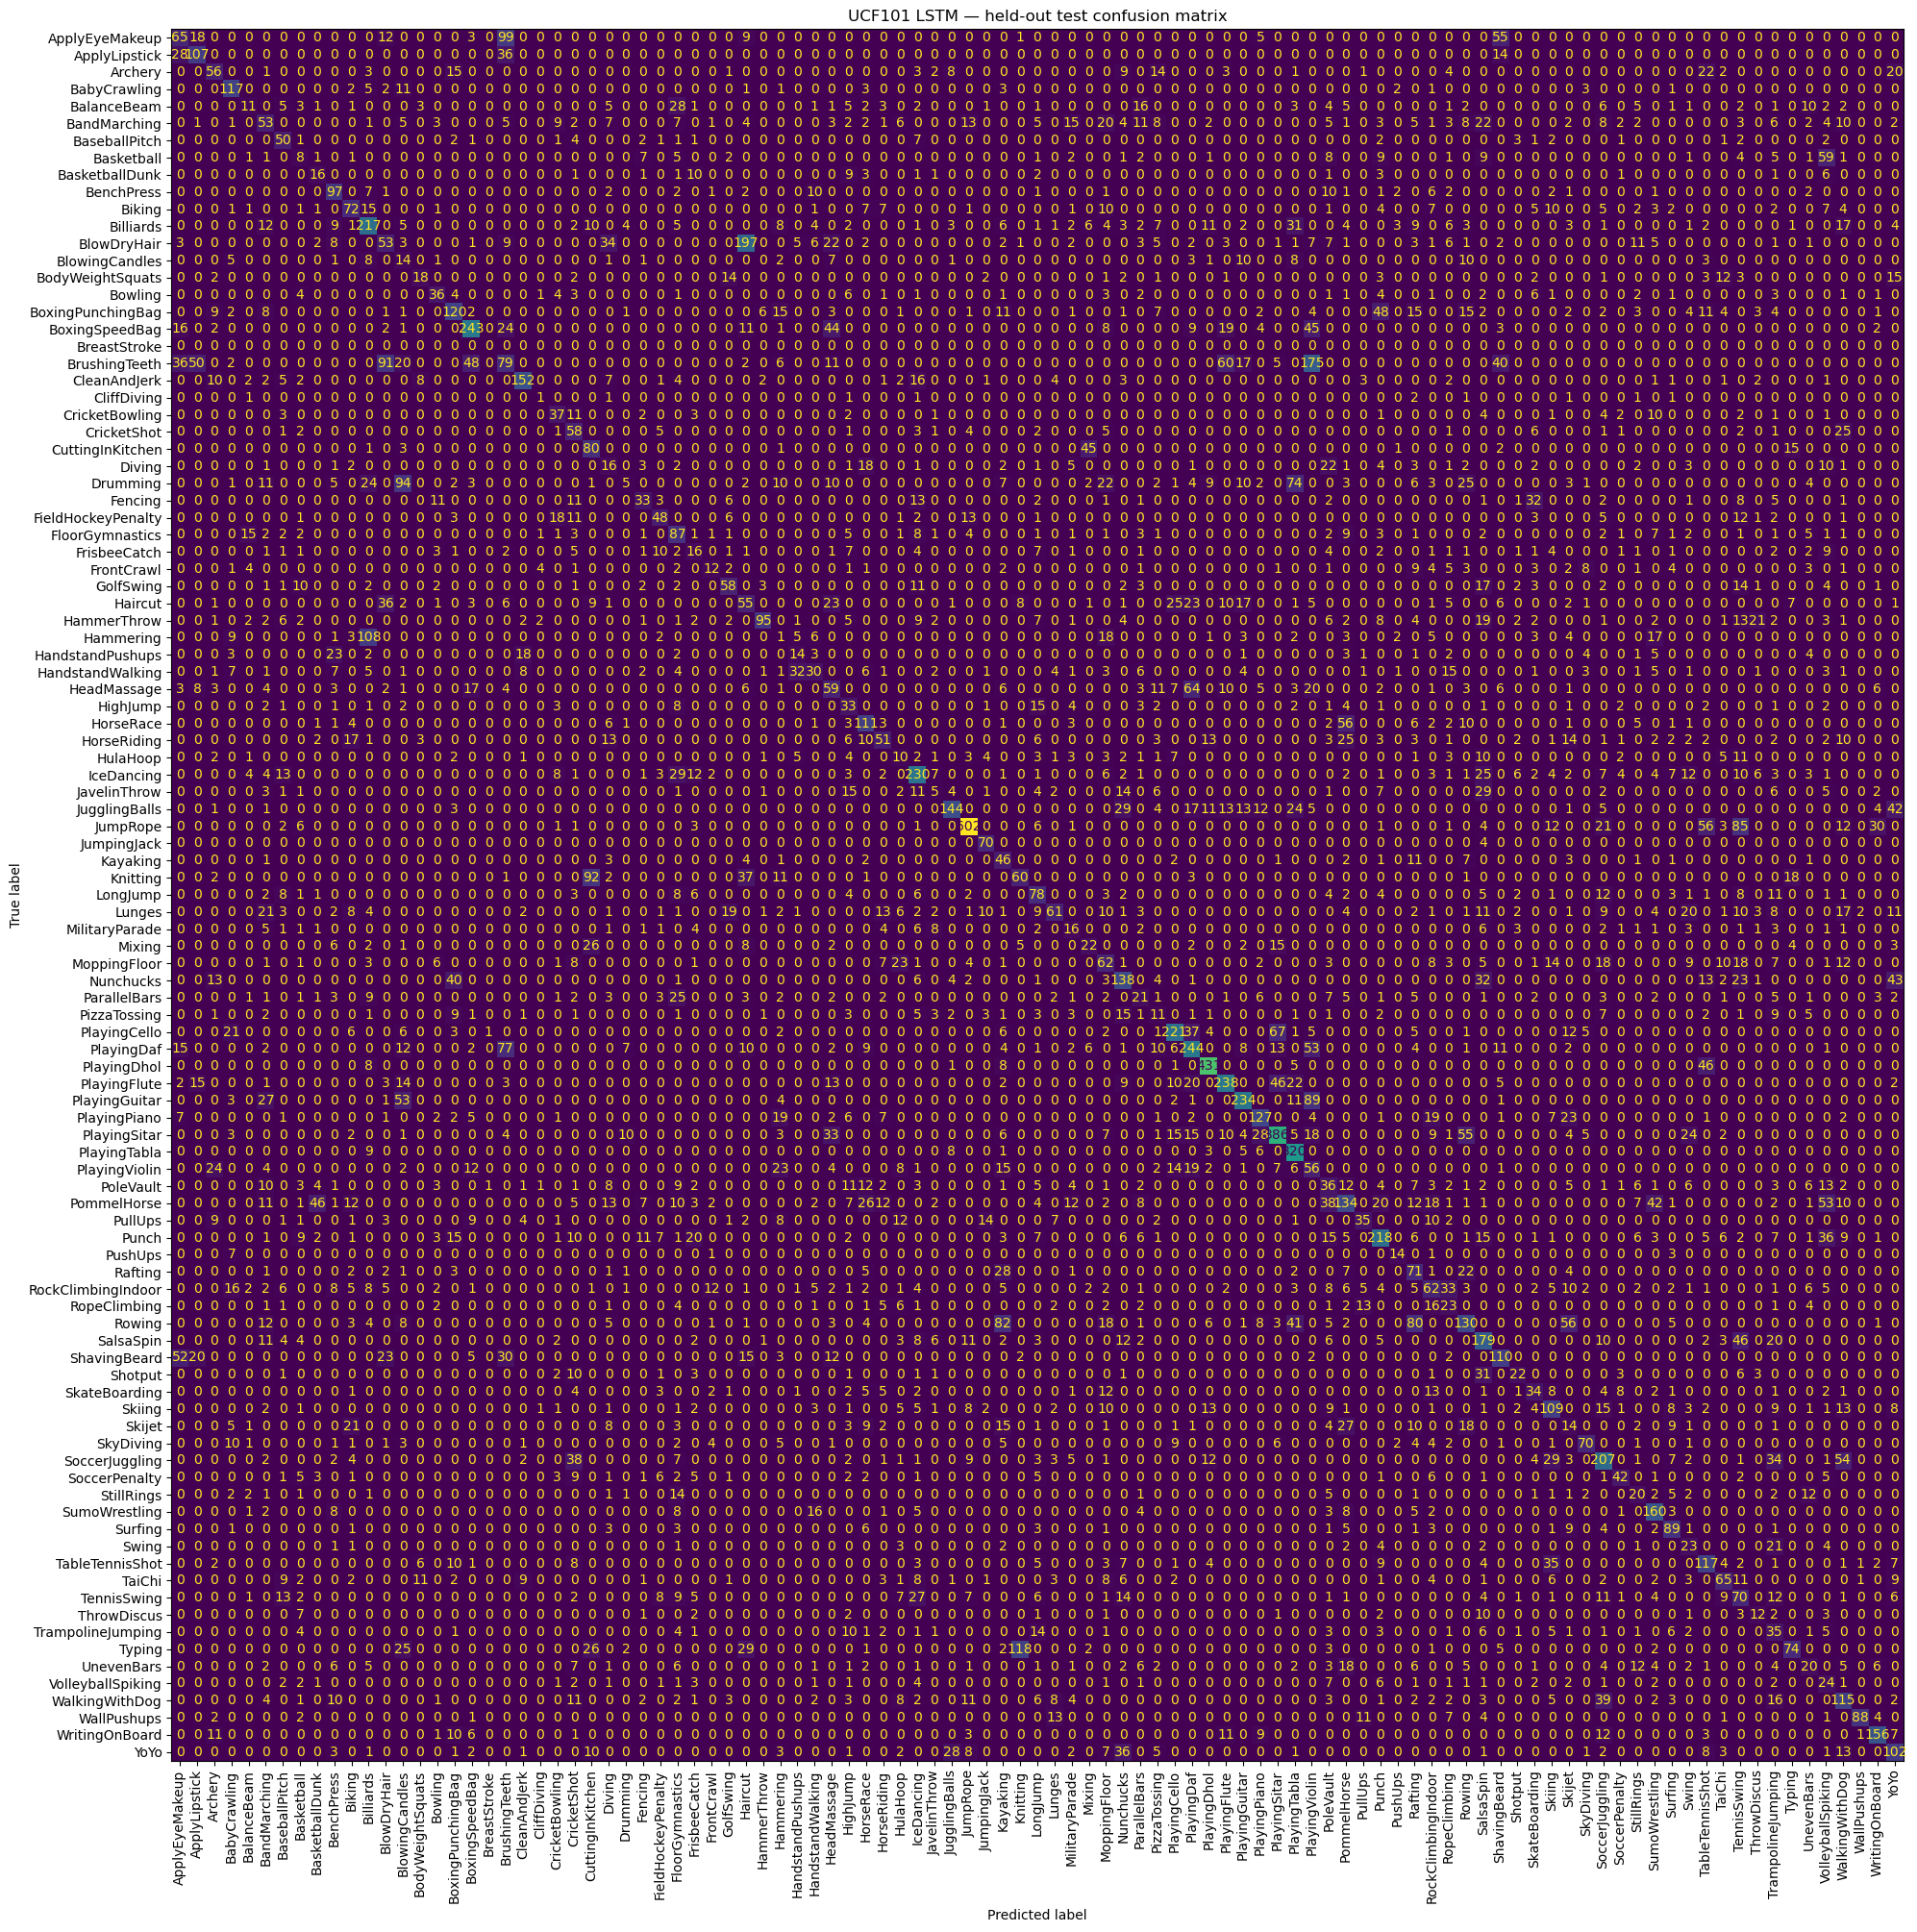

    true_label predicted_label  correct
ApplyEyeMakeup  ApplyEyeMakeup     True
ApplyEyeMakeup  ApplyEyeMakeup     True
ApplyEyeMakeup  ApplyEyeMakeup     True
ApplyEyeMakeup  ApplyEyeMakeup     True
ApplyEyeMakeup   ApplyLipstick    False
ApplyEyeMakeup   ApplyLipstick    False
ApplyEyeMakeup    ShavingBeard    False
ApplyEyeMakeup    ShavingBeard    False
ApplyEyeMakeup    ShavingBeard    False
ApplyEyeMakeup         Haircut    False
ApplyEyeMakeup    ShavingBeard    False
ApplyEyeMakeup  ApplyEyeMakeup     True
ApplyEyeMakeup  ApplyEyeMakeup     True
ApplyEyeMakeup  ApplyEyeMakeup     True
ApplyEyeMakeup  ApplyEyeMakeup     True
ApplyEyeMakeup  ApplyEyeMakeup     True
ApplyEyeMakeup  ApplyEyeMakeup     True
ApplyEyeMakeup  ApplyEyeMakeup     True
ApplyEyeMakeup  ApplyEyeMakeup     True
ApplyEyeMakeup  ApplyEyeMakeup     True

Saved report: C:\Users\admin\ViTPose_Action_Recognition\outputs\reports\lstm_ucf101_group_split_v1_classification_report.csv
Saved metrics: C:\Users\admin\ViTP

In [8]:
# Final test evaluation — run after model selection is complete
checkpoint = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True)
best_model = PoseLSTM(
    input_size=int(checkpoint["input_size"]),
    hidden_size=int(checkpoint["hidden_size"]),
    num_layers=int(checkpoint["num_layers"]),
    num_classes=int(checkpoint["num_classes"]),
    dropout=float(checkpoint["dropout"])
).to(DEVICE)
best_model.load_state_dict(checkpoint["model_state"], strict=True)
best_model.eval()

true_chunks, pred_chunks = [], []
with torch.inference_mode():
    for xb, yb in test_loader:
        logits = best_model(xb.to(DEVICE, non_blocking=(DEVICE.type == "cuda")))
        true_chunks.append(yb.numpy())
        pred_chunks.append(logits.argmax(dim=1).cpu().numpy())

y_true = np.concatenate(true_chunks).astype(np.int64)
y_pred = np.concatenate(pred_chunks).astype(np.int64)
labels_all = list(range(NUM_CLASSES))
metrics = {
    "test_accuracy": float(accuracy_score(y_true, y_pred)),
    "test_balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
    "test_macro_f1": float(f1_score(y_true, y_pred, labels=labels_all, average="macro", zero_division=0)),
    "best_epoch": int(checkpoint["best_epoch"]),
    "best_validation_macro_f1": float(checkpoint["best_val_macro_f1"]),
    "test_windows": int(len(y_true)),
    "test_source_videos": int(len(test_video_set)),
    "num_classes": int(NUM_CLASSES),
}
print("Best checkpoint epoch:", metrics["best_epoch"])
print("Test accuracy:", round(metrics["test_accuracy"], 4))
print("Test balanced accuracy:", round(metrics["test_balanced_accuracy"], 4))
print("Test macro-F1:", round(metrics["test_macro_f1"], 4))
print("Test windows:", metrics["test_windows"])
print("Test source videos:", metrics["test_source_videos"])

report_text = classification_report(y_true, y_pred, labels=labels_all,
                                    target_names=[id_to_label[i] for i in labels_all],
                                    zero_division=0)
print("\nClassification report:\n", report_text)
report_dict = classification_report(y_true, y_pred, labels=labels_all,
                                    target_names=[id_to_label[i] for i in labels_all],
                                    output_dict=True, zero_division=0)
report_csv = OUTPUT_REPORT_DIR / "lstm_ucf101_group_split_v1_classification_report.csv"
pd.DataFrame(report_dict).transpose().to_csv(report_csv)
metrics_path = OUTPUT_REPORT_DIR / "lstm_ucf101_group_split_v1_test_metrics.json"
metrics_path.write_text(json.dumps(metrics, indent=2), encoding="utf-8")

cm = confusion_matrix(y_true, y_pred, labels=labels_all)
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(max(12, NUM_CLASSES * 0.22), max(10, NUM_CLASSES * 0.20)))
cm_display.plot(ax=ax, xticks_rotation=90, colorbar=False, values_format="d")
ax.set_title("UCF101 LSTM — held-out test confusion matrix")
plt.tight_layout()
cm_path = OUTPUT_REPORT_DIR / "lstm_ucf101_group_split_v1_confusion_matrix.png"
plt.savefig(cm_path, dpi=160)
plt.show()

# Correct/predicted count table without shadowing IPython's display function.
compare_df = pd.DataFrame({
    "true_label": [id_to_label[int(i)] for i in y_true],
    "predicted_label": [id_to_label[int(i)] for i in y_pred],
    "correct": y_true == y_pred,
})
print(compare_df.head(20).to_string(index=False))
print("\nSaved report:", report_csv.resolve())
print("Saved metrics:", metrics_path.resolve())
print("Saved confusion matrix:", cm_path.resolve())

## Interpreting the result

- Use test accuracy together with **macro-F1** and balanced accuracy, since UCF101 classes may be imbalanced in the processed set.
- Do not compare results fairly if the source-video split changed between experiments.
- This is pose-based recognition, so performance depends on person detection and keypoint quality. It does not use RGB appearance features.
- The test set is held out by source video, but this does not automatically guarantee independence between very similar recordings; the extraction notebook attempts to diversify source recording groups only during optional per-class pilot selection.
- If the kernel runs out of memory, reduce `BATCH_SIZE` from 128 to 64 or 32. Feature arrays are memory-mapped, so they are not loaded fully into RAM.

In [9]:

from pathlib import Path
import json
import numpy as np
import pandas as pd

PROJECT_DIR = Path(r"C:\Users\admin\ViTPose_Action_Recognition")
DATA_DIR = PROJECT_DIR / "data" / "processed" / "sequences_group_split_v1"

# Load the saved integer-to-class-name mapping.
with open(DATA_DIR / "label_map.json", "r", encoding="utf-8") as f:
    label_map = json.load(f)

num_classes = len(label_map)
print("Number of classes:", num_classes)

# Count usable sequence windows in each split.
window_counts = {}
video_counts = {}

for split in ["train", "val", "test"]:
    y = np.load(DATA_DIR / f"y_{split}.npy", mmap_mode="r")
    videos = np.load(DATA_DIR / f"videos_{split}.npy", mmap_mode="r")

    counts = np.bincount(np.asarray(y, dtype=np.int64),
                         minlength=num_classes)
    window_counts[split] = counts

    video_counts[split] = {
        int(class_id): len(np.unique(videos[y == class_id]))
        for class_id in range(num_classes)
    }

    print(f"\n{split.upper()}:")
    print("  Total windows:", len(y))
    print("  Source videos:", len(np.unique(videos)))
    print("  Classes with zero windows:",
          [label_map[str(i)] for i, n in enumerate(counts) if n == 0])

# Check the per-video sequence summary for classes with zero usable windows.
summary_path = DATA_DIR / "video_sequence_summary.csv"

if summary_path.is_file():
    summary = pd.read_csv(summary_path)
    print("\nPer-class usable source videos by split:")

    usable = summary[summary["sequence_windows"] > 0]

    table = pd.crosstab(
        usable["label"], usable["split"]
    ).reindex(columns=["train", "val", "test"], fill_value=0)

    print(table.to_string())

    missing_test = table.index[table["test"] == 0].tolist()
    missing_val = table.index[table["val"] == 0].tolist()

    print("\nClasses without usable test videos:", missing_test)
    print("Classes without usable validation videos:", missing_val)

# Check that recording groups do not overlap between splits.
manifest_path = DATA_DIR / "video_split_manifest.csv"

if manifest_path.is_file():
    manifest = pd.read_csv(manifest_path)
    group_col = "recording_group_key"

    if group_col in manifest.columns and "split" in manifest.columns:
        groups = {
            s: set(manifest.loc[manifest["split"] == s, group_col].dropna())
            for s in ["train", "val", "test"]
        }

        print("\nRecording-group overlap:")
        for a, b in [("train", "val"), ("train", "test"),
                     ("val", "test")]:
            overlap = groups[a] & groups[b]
            print(f"{a} vs {b}: {len(overlap)} overlapping groups")


Number of classes: 101

TRAIN:
  Total windows: 61747
  Source videos: 7236
  Classes with zero windows: []

VAL:
  Total windows: 21815
  Source videos: 2454
  Classes with zero windows: []

TEST:
  Total windows: 21960
  Source videos: 2435
  Classes with zero windows: ['BreastStroke']

Per-class usable source videos by split:
split               train  val  test
label                               
ApplyEyeMakeup         88   27    30
ApplyLipstick          69   21    24
Archery                86   29    23
BabyCrawling           73   27    22
BalanceBeam            60   19    23
BandMarching           91   32    31
BaseballPitch          88   32    26
Basketball             69   26    23
BasketballDunk         53   20    25
BenchPress             88   26    32
Biking                 76   23    21
Billiards              81   31    31
BlowDryHair            81   25    25
BlowingCandles         47   19    16
BodyWeightSquats       65   20    17
Bowling                78   31    23
Box

In [10]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(r"C:\Users\admin\ViTPose_Action_Recognition")
SEQ_DIR = PROJECT_DIR / "data" / "processed" / "sequences_group_split_v1"

split_path = SEQ_DIR / "video_split_manifest.csv"
summary_path = SEQ_DIR / "video_sequence_summary.csv"

split_df = pd.read_csv(split_path)
summary_df = pd.read_csv(summary_path)

# Inspect every BreastStroke video, including videos that produced
# zero usable sequence windows.
bs = summary_df[
    summary_df["label"].astype(str).str.casefold() == "breaststroke"
].copy()

assert not bs.empty, "No BreastStroke rows found in the sequence summary."

bs["pose_success_rate"] = (
    bs["pose_successes"] /
    bs["sampled_frames"].clip(lower=1)
)

print("BreastStroke source videos:", len(bs))
print("Total usable sequence windows:", int(bs["sequence_windows"].sum()))
print("Videos with zero sequence windows:",
      int((bs["sequence_windows"] == 0).sum()))

print("\nBreastStroke summary by split:")
print(
    bs.groupby("split").agg(
        source_videos=("video_path", "nunique"),
        recording_groups=("recording_group_key", "nunique"),
        sampled_frames=("sampled_frames", "sum"),
        pose_successes=("pose_successes", "sum"),
        sequence_windows=("sequence_windows", "sum"),
    ).to_string()
)

print("\nBreastStroke videos with zero usable windows:")
cols = [
    "video_path", "recording_group_key", "split",
    "sampled_frames", "pose_successes",
    "pose_success_rate", "sequence_windows",
]
display(
    bs.loc[bs["sequence_windows"] == 0, cols]
      .sort_values(["split", "recording_group_key"])
      .head(40)
)

print("\nRecording groups assigned to each split:")
print(
    split_df[
        split_df["label"].astype(str).str.casefold() == "breaststroke"
    ].groupby("split").agg(
        videos=("video_path", "nunique"),
        groups=("recording_group_key", "nunique"),
    ).to_string()
)

BreastStroke source videos: 101
Total usable sequence windows: 23
Videos with zero sequence windows: 92

BreastStroke summary by split:
       source_videos  recording_groups  sampled_frames  pose_successes  sequence_windows
split                                                                                   
test              20                 5            1020             194                 0
train             60                15            2716             722                19
val               21                 5             890             160                 4

BreastStroke videos with zero usable windows:


,video_path,recording_group_key,split,sampled_frames,pose_successes,pose_success_rate,sequence_windows
2462,C:\Users\admin\ViTPose_Action_Recognition\data...,BreastStroke::g01,test,24,3,0.125000,0
2463,C:\Users\admin\ViTPose_Action_Recognition\data...,BreastStroke::g01,test,24,4,0.166667,0
2464,C:\Users\admin\ViTPose_Action_Recognition\data...,BreastStroke::g01,test,24,3,0.125000,0
2465,C:\Users\admin\ViTPose_Action_Recognition\data...,BreastStroke::g01,test,24,9,0.375000,0
2502,C:\Users\admin\ViTPose_Action_Recognition\data...,BreastStroke::g11,test,99,18,0.181818,0
2503,C:\Users\admin\ViTPose_Action_Recognition\data...,BreastStroke::g11,test,91,3,0.032967,0
2504,C:\Users\admin\ViTPose_Action_Recognition\data...,BreastStroke::g11,test,105,1,0.009524,0
2505,C:\Users\admin\ViTPose_Action_Recognition\data...,BreastStroke::g11,test,94,12,0.127660,0
2510,C:\Users\admin\ViTPose_Action_Recognition\data...,BreastStroke::g13,test,17,5,0.294118,0
2511,C:\Users\admin\ViTPose_Action_Recognition\data...,BreastStroke::g13,test,17,6,0.352941,0



Recording groups assigned to each split:
       videos  groups
split                
test       20       5
train      60      15
val        21       5


In [11]:
from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_DIR = Path(r"C:\Users\admin\ViTPose_Action_Recognition")
SEQ_DIR = PROJECT_DIR / "data" / "processed" / "sequences_group_split_v1"

summary = pd.read_csv(SEQ_DIR / "video_sequence_summary.csv")
bs = summary[
    summary["label"].astype(str).str.casefold() == "breaststroke"
].copy()

SEQUENCE_LENGTH = 16
SEQUENCE_STRIDE = 4
THRESHOLDS = [0.80, 0.50, 0.35]

def count_candidate_windows(npz_path):
    with np.load(npz_path, allow_pickle=False) as d:
        kps = np.asarray(d["keypoints"], dtype=np.float32)
        boxes = np.asarray(d["boxes"], dtype=np.float32)
        pose_ok = np.asarray(d["has_person"], dtype=bool)

    if (
        kps.ndim != 3 or kps.shape[1:] != (17, 3)
        or len(kps) != len(boxes) or len(kps) != len(pose_ok)
    ):
        return None, None

    valid = np.zeros(len(kps), dtype=bool)

    for i, (kp, box) in enumerate(zip(kps, boxes)):
        if not pose_ok[i]:
            continue
        if not np.isfinite(box).all():
            continue
        if not np.isfinite(kp[:, :2]).all():
            continue

        x1, y1, x2, y2 = box
        if x2 - x1 < 2 or y2 - y1 < 2:
            continue

        valid[i] = True

    if len(valid) < SEQUENCE_LENGTH:
        return valid.mean() if len(valid) else 0.0, {
            th: 0 for th in THRESHOLDS
        }

    starts = list(range(
        0, len(valid) - SEQUENCE_LENGTH + 1, SEQUENCE_STRIDE
    ))
    final_start = len(valid) - SEQUENCE_LENGTH
    if starts and starts[-1] != final_start:
        starts.append(final_start)

    ratios = [
        float(valid[s:s + SEQUENCE_LENGTH].mean())
        for s in starts
    ]

    counts = {
        th: sum(r >= th for r in ratios)
        for th in THRESHOLDS
    }

    return float(valid.mean()), counts


records = []

for _, row in bs.iterrows():
    try:
        mean_valid, candidate_counts = count_candidate_windows(
            row["source_npz"]
        )

        records.append({
            "label": row["label"],
            "split": row["split"],
            "video_path": row["video_path"],
            "mean_valid_frame_ratio": mean_valid,
            **{
                f"windows_at_{int(th * 100)}pct": (
                    candidate_counts[th] if candidate_counts else None
                )
                for th in THRESHOLDS
            },
        })
    except Exception as e:
        print("Could not inspect:", row["video_path"], repr(e))

audit = pd.DataFrame(records)

print("BreastStroke candidate windows by split and threshold:")
for th in THRESHOLDS:
    col = f"windows_at_{int(th * 100)}pct"
    print(f"\nThreshold {th:.0%}:")
    print(
        audit.groupby("split")[col]
        .sum(min_count=1)
        .fillna(0)
        .astype(int)
    )

print("\nVideos with the most potentially usable windows at 50%:")
display(
    audit.sort_values("windows_at_50pct", ascending=False)
    [["split", "video_path", "mean_valid_frame_ratio",
      "windows_at_80pct", "windows_at_50pct", "windows_at_35pct"]]
    .head(15)
)

BreastStroke candidate windows by split and threshold:

Threshold 80%:
split
test      0
train    19
val       4
Name: windows_at_80pct, dtype: int64

Threshold 50%:
split
test     15
train    88
val      12
Name: windows_at_50pct, dtype: int64

Threshold 35%:
split
test      51
train    157
val       27
Name: windows_at_35pct, dtype: int64

Videos with the most potentially usable windows at 50%:


,split,video_path,mean_valid_frame_ratio,windows_at_80pct,windows_at_50pct,windows_at_35pct
4,train,C:\Users\admin\ViTPose_Action_Recognition\data...,0.578947,0,10,12
11,train,C:\Users\admin\ViTPose_Action_Recognition\data...,0.702128,2,9,9
8,train,C:\Users\admin\ViTPose_Action_Recognition\data...,0.704545,1,8,8
88,train,C:\Users\admin\ViTPose_Action_Recognition\data...,0.481928,1,8,12
36,train,C:\Users\admin\ViTPose_Action_Recognition\data...,0.868421,6,7,7
87,train,C:\Users\admin\ViTPose_Action_Recognition\data...,0.529412,2,7,14
80,train,C:\Users\admin\ViTPose_Action_Recognition\data...,0.692308,2,7,7
63,val,C:\Users\admin\ViTPose_Action_Recognition\data...,0.555556,4,7,7
90,test,C:\Users\admin\ViTPose_Action_Recognition\data...,0.422222,0,7,14
9,train,C:\Users\admin\ViTPose_Action_Recognition\data...,0.666667,3,7,9
